# Семинар 4. SARSA и Q-learning руками: от игровых автоматов до такси — решение

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/solutions/week04/seminar.ipynb)

Задачи семинара — **репетиция домашнего задания блока 2**. На лекции функция `td_control` была готовой — сегодня вы пишете её ядро сами и прогоняете на трёх средах по нарастающей: сначала десять игровых автоматов, где нет даже состояний, затем знакомый обрыв, а в конце — новая среда, такси. Пуант: один и тот же код, написанный вами один раз, работает во всех трёх.

| | Что делаем | Раздел лекции | Минут | В домашке |
|---|---|---|---|---|
| 1 | ε-жадность на десяти автоматах | 1. Q-learning за три вопроса | 12 | ✓ |
| 2 | SARSA и Q-learning своими руками | 3–4. SARSA; обрыв рассудит | 28 | ✓ |
| 3 | Новая среда: такси | 2. как знакомиться с новой средой | 22 | ✓ |
| 4 | Расписание ε: почините SARSA | 4. дрожь оценок; предел ε → 0 | 23 | ✓ |
| 5 | Что дальше | — | 5 | — |

Эталонное решение семинара: все `TODO` заполнены, ноутбук выполнен. Разбирайте после того, как попробуете сами.

In [1]:
# Если ноутбук открыт в Google Colab: ставим недостающие пакеты. Локально (после uv sync) ячейка ничего не делает.
import importlib.util, subprocess, sys
if importlib.util.find_spec("gymnasium") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium"], check=True)

In [2]:
# Служебные модули: рисовальщики обрыва (лекция 3) и такси (этот семинар). В Colab скачиваются.
import pathlib, urllib.request
REPO = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/"
for path, local_dirs in [("03-value-based/lecture/td_plots.py", ["../../03-value-based/lecture"]),
                         ("04-sarsa/seminar/taxi_plots.py", ["", "../../04-sarsa/seminar"])]:
    name = pathlib.Path(path).name
    for d in local_dirs:
        if pathlib.Path(d, name).exists():
            sys.path.append(d)
            break
    else:
        urllib.request.urlretrieve(REPO + path, name)

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from td_plots import draw_cliff, greedy_path, plot_curves, smooth, CLIFF_GOAL
from taxi_plots import make_taxi, draw_taxi, play_episode, average_greedy_return

## 1. ε-жадность на десяти автоматах

Самая простая «среда», какая только бывает: десять игровых автоматов, состояние всегда одно и то же, эпизод — один розыгрыш. Агент видит только свои выигрыши; скрытые средние автоматов — в массиве `MEANS`, подглядывать в него агент не может. Всё, что нужно для игры, — та самая функция из лекции.

**TODO 1.1. ε-жадный выбор.** Напишите `epsilon_greedy` — с вероятностью `eps` случайное действие, иначе лучшее по строке `Q[s]` (ничьи разрешайте случайно — в начале обучения вся строка из нулей).

In [3]:
MEANS = np.round(np.random.default_rng(7).normal(0, 1, 10), 2)   # скрытые средние выигрыши автоматов

def epsilon_greedy(Q, s, eps, rng):
    """С вероятностью eps — случайное действие, иначе лучшее по строке Q[s] (ничьи — случайно)."""
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))

# Проверка 1.1 — строка таблицы из вопроса 1 лекции
rng = np.random.default_rng(0)
Q_demo = np.array([[0.10, -1.00, 0.20, 0.40]])
assert all(epsilon_greedy(Q_demo, 0, 0.0, rng) == 3 for _ in range(100)), \
    "при eps = 0 выбор всегда жадный: действие 3 (+0.40)"
freq = np.mean([epsilon_greedy(Q_demo, 0, 0.2, rng) == 3 for _ in range(100_000)])
assert 0.84 < freq < 0.86, f"при eps = 0.2 лучшее действие выбирается с частотой 0.8 + 0.2/4 = 0.85, у вас {freq:.3f}"
print(f"OK: частота лучшего действия {freq:.3f} — как в вопросе 3 лекции")

OK: частота лучшего действия 0.849 — как в вопросе 3 лекции


Теперь сыграем. Цикл обучения дан готовым: оценка каждого автомата — среднее его выигрышей, посчитанное на ходу с $\alpha = 1/n$ (лекция 3, раздел 4).

**Прикиньте, потом проверьте:** при каком ε агент к тысячному шагу чаще всего играет на лучшем автомате — 0, 0.1 или 0.5? И почему вариант «вообще без случайных шагов» может подвести?

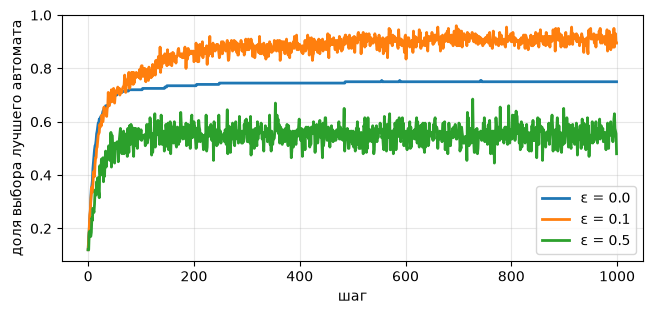

In [4]:
def play_bandit(eps, n_steps=1000, n_runs=200):
    """Доля запусков, в которых на шаге t выбран лучший автомат (усреднение по n_runs запускам)."""
    best, hits = MEANS.argmax(), np.zeros(n_steps)
    for run in range(n_runs):
        rng = np.random.default_rng(run)              # свой генератор на каждый запуск
        Q, N = np.zeros((1, 10)), np.zeros(10)
        for t in range(n_steps):
            a = epsilon_greedy(Q, 0, eps, rng)
            win = rng.normal(MEANS[a], 1)             # один розыгрыш автомата a
            N[a] += 1
            Q[0, a] += (win - Q[0, a]) / N[a]         # среднее на ходу, α = 1/n (лекция 3)
            hits[t] += a == best
    return hits / n_runs

plt.figure(figsize=(7.5, 3.2))
for eps in (0.0, 0.1, 0.5):
    plt.plot(play_bandit(eps), lw=2, label=f"ε = {eps}")
plt.xlabel("шаг"); plt.ylabel("доля выбора лучшего автомата")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Что видно на кривых (числа — доля на последних ста шагах):

* **ε = 0** выходит на 0.75 и застревает: примерно в каждом четвёртом запуске ранний «везунчик» среди худших автоматов закрепляется навсегда — без случайных шагов его некому перепроверить. Это смещение максимума из лекции в действии.
* **ε = 0.1** добирается до 0.91 — и выше не поднимется никогда: $0.9 + 0.1/10 = 0.91$, десятая часть шагов навсегда уходит на исследование.
* **ε = 0.5** слишком щедрый: половина шагов случайные, доля лучшего — около 0.55.

**Обсудите.** Как получить и раннее исследование, и позднюю точность сразу? (Эту идею мы доведём до кода в разделе 4.)

## 2. SARSA и Q-learning своими руками

Ядро лекции — два обновления, различающиеся одним словом в цели:

$$
\text{SARSA: } \text{цель} = r + \gamma\, Q(s', a')
\qquad\qquad
\text{Q-learning: } \text{цель} = r + \gamma \max_{a'} Q(s', a')
$$

Пишем оба — по шагам, каждый шаг проверяется числами, которые считаются в уме.

**TODO 2.1. Одно обновление SARSA.** Цель $r + \gamma\, Q[s_2, a_2]$ (у терминального перехода будущего нет — флаг `done`), затем сдвиг $Q[s, a]$ к цели на долю $\alpha$.

In [5]:
def sarsa_step(Q, s, a, r, s2, a2, done, alpha, gamma):
    """Одно обновление SARSA: цель r + gamma * Q[s2, a2]; если done — просто r."""
    target = r + gamma * (0.0 if done else Q[s2, a2])
    Q[s, a] += alpha * (target - Q[s, a])

# Проверка 2.1 — числа из вопроса 2 лекции
Q = np.zeros((2, 4)); Q[0, 0] = 0.30; Q[1, 2] = 0.50
sarsa_step(Q, s=0, a=0, r=0.0, s2=1, a2=2, done=False, alpha=0.1, gamma=1.0)
assert np.isclose(Q[0, 0], 0.32), f"0.30 + 0.1 · (0.50 − 0.30) = 0.32, у вас {Q[0, 0]:.3f}"
sarsa_step(Q, s=0, a=1, r=1.0, s2=1, a2=2, done=True, alpha=0.5, gamma=1.0)
assert np.isclose(Q[0, 1], 0.5), "после терминального перехода цель — это просто r: 0 + 0.5 · (1 − 0) = 0.5"
print("OK: одно обновление SARSA")

OK: одно обновление SARSA


In [6]:
def q_step(Q, s, a, r, s2, a2, done, alpha, gamma):
    """Одно обновление Q-learning: в цели вместо Q[s2, a2] — максимум строки Q[s2]; a2 игнорируется."""
    target = r + gamma * (0.0 if done else Q[s2].max())
    Q[s, a] += alpha * (target - Q[s, a])

# Проверка 2.2 — та же ситуация, но в строке s2 есть действие получше, чем выбранное
Q = np.zeros((2, 4)); Q[0, 0] = 0.30; Q[1, 2] = 0.50; Q[1, 3] = 0.90
q_step(Q, s=0, a=0, r=0.0, s2=1, a2=2, done=False, alpha=0.1, gamma=1.0)
assert np.isclose(Q[0, 0], 0.36), f"цель Q-learning берёт максимум строки: 0.30 + 0.1 · (0.90 − 0.30) = 0.36, у вас {Q[0, 0]:.3f}"
print("OK: одно обновление Q-learning; SARSA в этой же ситуации дал бы 0.32")

OK: одно обновление Q-learning; SARSA в этой же ситуации дал бы 0.32


**TODO 2.3. Цикл обучения.** Каркас готов: он играет эпизоды, выбирает действия ε-жадно и записывает return'ы; строка с затуханием ε уже на месте — она понадобится в разделе 4. Ваше дело — одна строка: применить `step_fn` к пятёрке.

Проверка — обрыв из лекции с тем же seed: ваши числа должны совпасть с лекционными.

In [7]:
def train(env, step_fn, n_episodes=500, eps=0.1, alpha=0.5, gamma=1.0, seed=0,
          max_steps=500, eps_decay=1.0, eps_min=0.0):
    """Обучение step_fn (sarsa_step или q_step) на любой среде Gymnasium с дискретными состояниями.

    После каждого эпизода eps умножается на eps_decay, но не опускается ниже eps_min (раздел 4)."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    returns, e = [], eps
    for episode in range(n_episodes):
        s, _ = env.reset(seed=int(rng.integers(1_000_000)))
        a = epsilon_greedy(Q, s, e, rng)
        total = 0.0
        for t in range(max_steps):
            s2, r, terminated, truncated, _ = env.step(a)
            a2 = epsilon_greedy(Q, s2, e, rng)        # следующее действие выбрано заранее: это a' из пятёрки
            step_fn(Q, s, a, r, s2, a2, terminated, alpha, gamma)
            total += r
            s, a = s2, a2
            if terminated or truncated:
                break
        returns.append(total)
        e = max(eps_min, e * eps_decay)               # расписание ε — раздел 4
    return Q, np.array(returns)

# Проверка 2.3 — обрыв, seed как в лекции: жадные пути и выигрыш SARSA при обучении
cliff = gym.make("CliffWalking-v1")
Q_sarsa, ret_sarsa = train(cliff, sarsa_step, seed=2)
Q_ql, ret_ql = train(cliff, q_step, seed=2)
path_sarsa, path_ql = greedy_path(Q_sarsa), greedy_path(Q_ql)
assert len(path_ql) - 1 == 13, f"жадный путь Q-learning — 13 шагов вдоль края, у вас {len(path_ql) - 1}"
assert len(path_sarsa) - 1 == 17, f"жадный путь SARSA — обход в 17 шагов, у вас {len(path_sarsa) - 1}"
assert ret_sarsa[-100:].mean() > ret_ql[-100:].mean(), \
    "во время обучения SARSA должен набирать больше: он учитывает свои случайные шаги, Q-learning — нет"
print(f"OK: пути {len(path_ql) - 1} и {len(path_sarsa) - 1} шагов; return последних 100 эпизодов "
      f"{ret_ql[-100:].mean():+.1f} (Q-learning) против {ret_sarsa[-100:].mean():+.1f} (SARSA)")

OK: пути 13 и 17 шагов; return последних 100 эпизодов -60.6 (Q-learning) против -25.5 (SARSA)


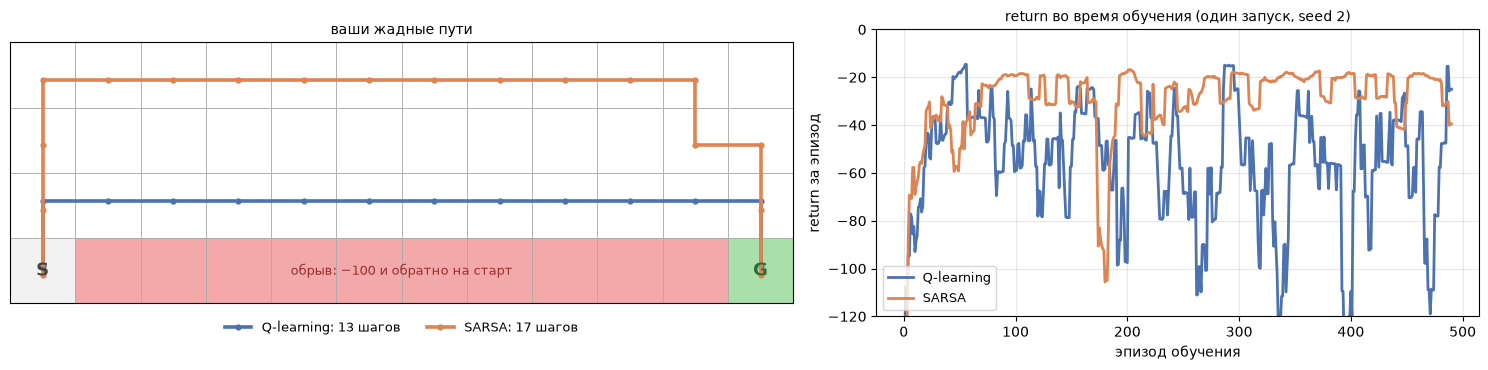

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
draw_cliff({"Q-learning": path_ql, "SARSA": path_sarsa}, ax=axes[0], title="ваши жадные пути")
plot_curves({"Q-learning": ret_ql[None], "SARSA": ret_sarsa[None]}, ax=axes[1],
            title="return во время обучения (один запуск, seed 2)")
plt.tight_layout(); plt.show()

Та же картина, что на лекции: Q-learning идёт по краю, SARSA — в обход, и во время обучения SARSA набирает примерно вдвое больше.

**Обсудите.** Путь Q-learning короче, а return при обучении хуже. В каких задачах вы предпочли бы агента Q-learning, а в каких — SARSA? (Подсказка из лекции: выключат ли случайность после обучения.)

## 3. Новая среда: такси

Знакомиться с новой средой будем по чек-листу лекции: что такое состояние, какие действия, за что награды, когда конец эпизода.

**Такси** — классика Gymnasium: поле 5 × 5 с четырьмя остановками R, G, Y, B. Пассажир ждёт на одной из остановок, его нужно отвезти на другую. Награды: каждый шаг $-1$, посадка или высадка не там $-10$, довезли — $+20$. Эпизод обрезается на 200 шагах.

* **Состояний 500** = 25 позиций такси × 5 мест пассажира × 4 цели.
* **Действий 6**: четыре движения, «посадить», «высадить».

Запустим и посмотрим.

состояний: 500   действий: 6
decode(s) → (ряд такси, столбец, где пассажир, куда везти): [0, 2, 0, 2]


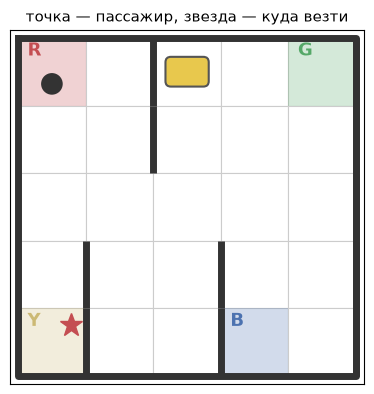

случайный таксист, 100 эпизодов: средний return -786.3


In [9]:
taxi = make_taxi()                                    # Taxi-v4; в старых версиях gymnasium — Taxi-v3
s, _ = taxi.reset(seed=3)
print("состояний:", taxi.observation_space.n, "  действий:", taxi.action_space.n)
print("decode(s) → (ряд такси, столбец, где пассажир, куда везти):", list(taxi.unwrapped.decode(s)))
draw_taxi(taxi, s, title="точка — пассажир, звезда — куда везти"); plt.show()

random_returns = [sum(play_episode(taxi, Q=None, seed=i)[2]) for i in range(100)]
print(f"случайный таксист, 100 эпизодов: средний return {np.mean(random_returns):+.1f}")

Минус восемьсот за эпизод: случайный таксист двести шагов мечется по полю и то и дело жмёт «посадить» посреди улицы:

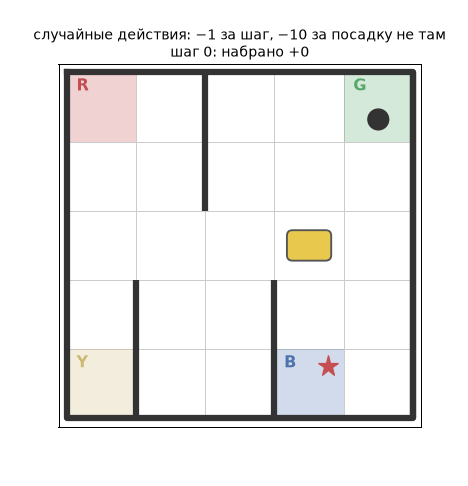

**Обсудите.** Почему мест пассажира пять, если остановок четыре? И почему состояний именно 25 · 5 · 4, хотя агент видит одно число `s`?

**TODO 3.1. Такси выучивается вашим же кодом.** Функция `train` из раздела 2 про такси не знает ничего — и этого достаточно. Обучите Q-learning: 2000 эпизодов, `alpha=0.3`, `eps=0.1`, `max_steps=200`, seed 0 — и посчитайте результат жадной стратегии через `average_greedy_return(taxi, Q_taxi)`. Две строки.

In [10]:
Q_taxi, ret_taxi = train(taxi, q_step, n_episodes=2000, alpha=0.3, eps=0.1, max_steps=200, seed=0)
greedy_result = average_greedy_return(taxi, Q_taxi)

# Проверка 3.1
assert greedy_result > 0, \
    f"обученный таксист должен в среднем зарабатывать (эталон около +7.7), у вас {greedy_result:+.1f}"
print(f"OK: жадный таксист в среднем {greedy_result:+.1f} за эпизод (случайный: {np.mean(random_returns):+.1f})")

OK: жадный таксист в среднем +7.7 за эпизод (случайный: -786.3)


Из минус восьмисот в плюс — те же несколько строчек кода, что и на обрыве. Вот как выглядит выученное поведение:

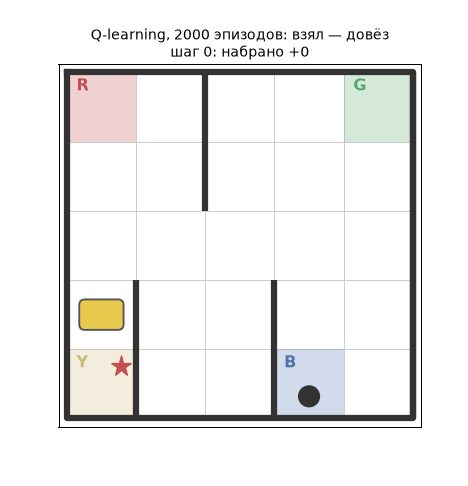

Посмотрите эпизод своего агента — три кадра: старт, середина, высадка.

жадный эпизод: 15 шагов, return +6


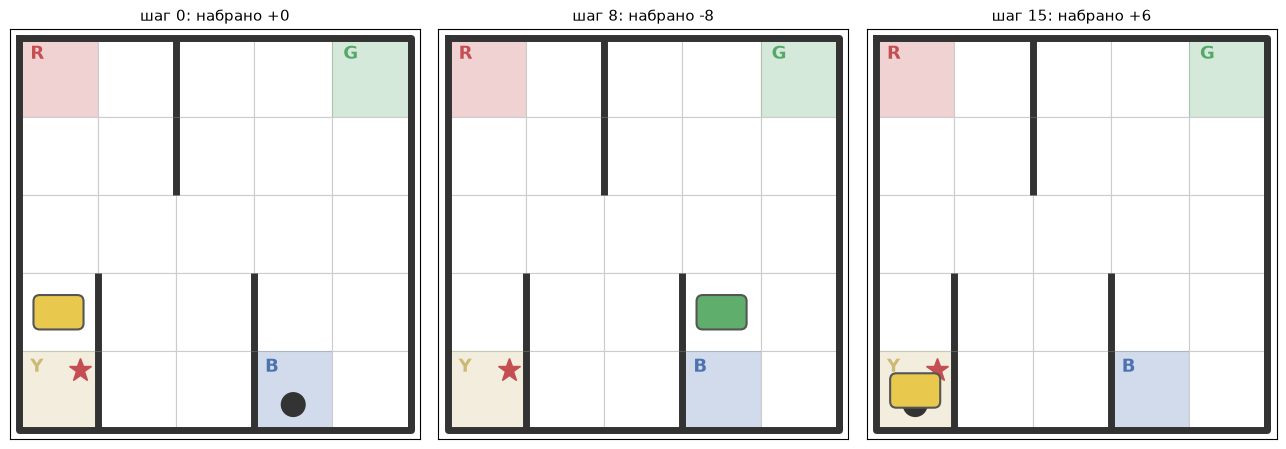

In [11]:
states, actions, rewards = play_episode(taxi, Q_taxi, seed=0)
print(f"жадный эпизод: {len(rewards)} шагов, return {sum(rewards):+d}")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, k in zip(axes, [0, len(states) // 2, len(states) - 1]):
    draw_taxi(taxi, states[k], ax=ax, title=f"шаг {k}: набрано {sum(rewards[:k]):+d}")
plt.tight_layout(); plt.show()

## 4. Расписание ε: почините SARSA

**Прикиньте, потом проверьте.** Обучим на такси SARSA — с теми же настройками, что Q-learning (ε = 0.1, 5000 эпизодов). Во время обучения он наберёт прилично. А что покажет его **жадная** стратегия?

In [12]:
Q_s, ret_s = train(taxi, sarsa_step, n_episodes=5000, alpha=0.3, eps=0.1, max_steps=200, seed=0)
print(f"SARSA: во время обучения (посл. 100) {ret_s[-100:].mean():+.1f}, "
      f"жадная стратегия {average_greedy_return(taxi, Q_s):+.1f}")

SARSA: во время обучения (посл. 100) +0.5, жадная стратегия -34.3


Во время обучения всё неплохо, а жадная стратегия проваливается: около $-34$ (на других seed — около нуля, но до Q-learning всё равно далеко). Ничего не сломалось: SARSA честно выучил ценность **ε-жадной** стратегии, а жадная по этой таблице — другая стратегия, и кое-где она водит такси кругами. Это та же «дрожь», из-за которой на обрыве SARSA в двух запусках из десяти упирался в стену.

Лекарство — прямиком из лекции: в пределе $\varepsilon \to 0$ цель SARSA превращается в цель Q-learning. Будем **гасить ε по ходу обучения**: начать с 1 (чистое исследование) и умножать на 0.999 после каждого эпизода, пока не дойдём до 0.01. И исследование раннее, и точность поздняя — ответ на вопрос из раздела 1.

**TODO 4.1. Затухание ε.** Каркас `train` уже умеет: параметры `eps=1.0, eps_decay=0.999, eps_min=0.01`. Переобучите SARSA (5000 эпизодов, `alpha=0.3`, seed 0) и посчитайте жадный результат. Две строки.

In [13]:
Q_decay, ret_decay = train(taxi, sarsa_step, n_episodes=5000, alpha=0.3,
                           eps=1.0, eps_decay=0.999, eps_min=0.01, max_steps=200, seed=0)
greedy_decay = average_greedy_return(taxi, Q_decay)

# Проверка 4.1
assert greedy_decay > 5, \
    f"затухание ε чинит жадную стратегию SARSA: эталон около +7.5, у вас {greedy_decay:+.1f}"
print(f"OK: SARSA с затуханием — жадная стратегия {greedy_decay:+.1f}, "
      f"обучение (посл. 100) {ret_decay[-100:].mean():+.1f}")

OK: SARSA с затуханием — жадная стратегия +7.5, обучение (посл. 100) +7.3


Жадная стратегия починилась — и само обучение к концу идёт почти без случайных штрафов. Сравним три кривые:

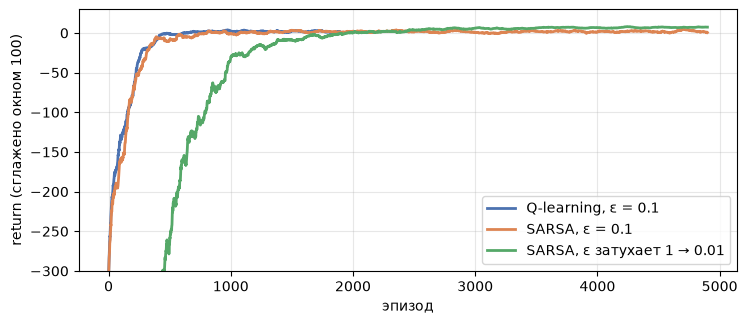

In [14]:
from taxi_plots import C_AGENT, C_REWARD, C_ENV
plt.figure(figsize=(8.5, 3.4))
for name, r, color in [("Q-learning, ε = 0.1", ret_taxi, C_AGENT),
                       ("SARSA, ε = 0.1", ret_s, C_REWARD),
                       ("SARSA, ε затухает 1 → 0.01", ret_decay, C_ENV)]:
    plt.plot(smooth(r, 100), lw=2, label=name, color=color)
plt.ylim(-300, 30); plt.xlabel("эпизод"); plt.ylabel("return (сглажено окном 100)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Кривая с затуханием стартует хуже всех (ε = 1 — чистый кубик), а заканчивает лучше всех: в конце она почти не делает случайных шагов.

**Эксперимент-соревнование.** Код писать не нужно — меняйте числа. Бюджет фиксированный: **3000 эпизодов**. Всё остальное — алгоритм, `alpha`, `eps`, `eps_decay`, `eps_min` — на ваш вкус. Чей агент наберёт лучший средний return за последние 500 эпизодов обучения? Параметры победителя — на доску.

In [15]:
# Поле для экспериментов: бюджет 3000 эпизодов, остальное меняйте
Q_my, ret_my = train(taxi, q_step, n_episodes=3000, alpha=0.3,
                     eps=1.0, eps_decay=0.999, eps_min=0.01, max_steps=200, seed=0)
print(f"обучение (посл. 500): {ret_my[-500:].mean():+.1f}   жадный: {average_greedy_return(taxi, Q_my):+.1f}")

обучение (посл. 500): +4.9   жадный: +7.7


**★ TODO 4.2. Double Q-learning.** Из лекции: максимум шумных оценок завышен, лечение — две таблицы: одна выбирает действие, другая его оценивает, и на каждом шаге они случайно меняются ролями. В домашке блока 2 он понадобится — каркас уже здесь.

In [16]:
def train_double(env, n_episodes=5000, eps=0.1, alpha=0.3, gamma=1.0, seed=0, max_steps=200):
    """★ Double Q-learning: действия выбирает сумма таблиц, обновляется случайная из двух."""
    rng = np.random.default_rng(seed)
    Q_A = np.zeros((env.observation_space.n, env.action_space.n))
    Q_B = np.zeros_like(Q_A)
    for episode in range(n_episodes):
        s, _ = env.reset(seed=int(rng.integers(1_000_000)))
        for t in range(max_steps):
            a = epsilon_greedy(Q_A + Q_B, s, eps, rng)
            s2, r, terminated, truncated, _ = env.step(a)
            if rng.random() < 0.5:
                best = int(np.argmax(Q_A[s2]))
                Q_A[s, a] += alpha * (r + gamma * (0.0 if terminated else Q_B[s2, best]) - Q_A[s, a])
            else:
                best = int(np.argmax(Q_B[s2]))
                Q_B[s, a] += alpha * (r + gamma * (0.0 if terminated else Q_A[s2, best]) - Q_B[s, a])
            s = s2
            if terminated or truncated:
                break
    return Q_A, Q_B

Q_A, Q_B = train_double(taxi)
double_result = average_greedy_return(taxi, Q_A + Q_B)
assert double_result > 0, f"Double Q должен довозить (эталон около +7.7), у вас {double_result:+.1f}"
print(f"OK: Double Q-learning, жадный результат {double_result:+.1f}")

OK: Double Q-learning, жадный результат +7.7


## 5. Что дальше

* Сегодня вы написали руками всё ядро value-based RL: ε-жадный выбор, обновления SARSA и Q-learning, цикл обучения, расписание ε и ★ Double Q — и один и тот же код отработал на автоматах, обрыве и такси.
* **Домашнее задание блока 2** строится ровно на этом: те же алгоритмы, те же среды, плюс эксперименты с расписаниями ε и α.
* **Квиз недели 4** — на [странице квизов](https://ilyachichkanov.github.io/Reinforcement-learning/); там же [песочница](https://ilyachichkanov.github.io/Reinforcement-learning/lecture04.html#sandbox) с обрывом.